<a href="https://colab.research.google.com/github/rokeya160210/Skin-Cancer-2-papers-comparison/blob/main/02_retrain_lesion_split_5seeds.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 — Retraining the ensemble arms with a lesion-disjoint split (revision run)

**Answers reviewer points #2, #7, #8, #10. It also produces the validation-set predictions needed for #9, #16 and #17.**

What changed from the submitted manuscript's training notebook (`ABLATION_H2_vs_H3_controlled.ipynb`, Part B). Nothing else changed.

| Change | Reviewer | Old | New |
|---|---|---|---|
| HAM10000 train/val split | #2 | image-level stratified 90/10 (8,719 / 969 images) | **lesion-level** stratified 90/10 on `lesion_id`; disjointness asserted |
| Gaussian-noise augmentation | #8 | `GaussianNoise(10/255)` applied to the 0–255 tensor **before** `Rescaling(1/255)` → SD ≈ 0.00015 on the [0,1] scale (no effect) | `GaussianNoise(10/255)` applied **after** `Rescaling(1/255)` → SD = 0.039 on [0,1] (10 grey levels), as intended. ConvNeXt gets the same noise and is then rescaled back to 0–255. Checked numerically in cell 5b |
| Seeds | #10 | 42, 1000, 50000 | **42, 1000, 50000, 2024, 31415** (fixed before any revision run) |
| Checkpoints / history | #7 | final weights used, `best.keras` (val_accuracy) saved but unused | fixed 50 epochs, **final-epoch weights = primary**; min-val-loss checkpoint saved and evaluated as a sensitivity analysis; per-epoch history + epoch time logged |
| Saved predictions | #9, #16, #17 | Derm7pt test probabilities only | test **and HAM validation** probabilities, for both checkpoints |
| Resource logging | #18 | — | peak GPU memory during training, wall-clock per epoch |

Unchanged on purpose: architectures, heads, Adam 1e-4, 50 epochs, batch 16 (controlled) / 32 (H2-original), balanced class weights, horizontal flip, ConvNeXt base frozen, ConvNeXt fed raw 0–255, the H2-original decode path, `reshuffle_each_iteration=False` (the original harness), and the Derm7pt test set (fingerprint asserted).

## How to run

One session = one `(ARM, SEED)`. Set them in CONFIG and run all cells. If Colab disconnects, re-run all cells: finished backbones are skipped and the interrupted one resumes from its last epoch. Each resume is counted in the manifest.

Run all 10 combinations: `ARM ∈ {controlled, h2_original}` × `SEED ∈ {42, 1000, 50000, 2024, 31415}`. Then run notebook 03.

> New results go to `skin_ablation_v2/`. Your submitted-manuscript runs in `skin_ablation/` are never touched.

## 1. CONFIG (the only cell you edit)

In [3]:
import os, json
ARM  = "h2_original"      # "controlled" (InceptionV3+DenseNet121+ConvNeXt-L, shared harness) | "h2_original"
SEED = 42                # one of SEEDS

SEEDS = [42, 1000, 50000, 2024, 31415]       # fixed before any revision run (reviewer #10)
assert SEED in SEEDS

# ---------------- shared harness (unchanged from the manuscript) -------------
IMG_SIZE    = (224, 224)
BATCH_SIZE  = 16          # controlled arm
LR          = 1e-4
EPOCHS      = 50
VAL_SPLIT   = 0.10        # fraction of LESIONS held out for validation
NUM_CLASSES = 6
USE_CLASS_WEIGHTS = True
FINE_TUNE_BASE = True             # InceptionV3 / DenseNet121
CONVNEXT_FINE_TUNE_BASE = False   # ConvNeXt-Large frozen
INCEPTION_FC_UNITS, DENSENET_CONV_FILTERS = 512, 512
DENSENET_FC1_UNITS, DENSENET_FC2_UNITS, CONVNEXT_FC_UNITS = 1024, 512, 512
RESHUFFLE_EACH_EPOCH = False      # the original harness shuffled once; kept so only the reviewed items change

# ---------------- augmentation (reviewer #8: corrected) ---------------------
USE_AUGMENTATION = True
AUG_HFLIP = True
NOISE_STDDEV_01 = 10.0 / 255.0   # SD on the [0,1] scale (= 10 grey levels), applied AFTER Rescaling(1/255)
# Keras 3 GaussianNoise only accepts stddev in [0, 1], so the noise must live on the rescaled [0,1] tensor.

# ---------------- original H2 harness (ARM = "h2_original") ------------------
H2_ORIG_BATCH_SIZE = 32
H2_ORIG_USE_AUGMENTATION = False
H2_ORIG_ACCURATE_DECODE = False

# ---------------- checkpoint policy (reviewer #7) ---------------------------
PRIMARY_CHECKPOINT = "final"            # final-epoch weights are the reported model
SENSITIVITY_CHECKPOINT = "best_val_loss"  # evaluated and reported as a sensitivity analysis

# ---------------- Google Drive storage -------------------------------------
# Checkpoints are only needed until a backbone's predictions are saved. Deleting them afterwards keeps Drive
# usage to ~2.5 GB (one seed in progress) instead of ~16 GB for all runs. History, predictions and the
# manifest are always kept. Set False only if you want to deposit the checkpoints (e.g. on Zenodo).
DELETE_CHECKPOINTS_WHEN_DONE = True

# ---------------- classes / Derm7pt -----------------------------------------
COMMON_CLASSES = ["MEL", "NV", "BCC", "BKL", "DF", "VASC"]
CLASS_TO_IDX = {c: i for i, c in enumerate(COMMON_CLASSES)}
IDX_TO_CLASS = {i: c for c, i in CLASS_TO_IDX.items()}
HAM_DX_TO_CLASS = {"mel": "MEL", "nv": "NV", "bcc": "BCC", "bkl": "BKL", "df": "DF", "vasc": "VASC"}
DERM7PT_DIAG_TO_CLASS = [("melanoma", "MEL"), ("nevus", "NV"), ("basal cell carcinoma", "BCC"),
                         ("seborrheic keratosis", "BKL"), ("dermatofibroma", "DF"), ("vascular", "VASC")]
EXPECTED_DERM7PT_COUNTS = {"NV": 575, "MEL": 252, "BKL": 45, "BCC": 42, "VASC": 29, "DF": 20}
EXPECTED_TEST_ORDER_FINGERPRINT = "bba3ea9a777c1eb1"   # identical to the manuscript runs

# ---------------- determinism (must precede `import tensorflow`) -------------
os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["TF_DETERMINISTIC_OPS"] = "1"
os.environ["TF_CUDNN_DETERMINISTIC"] = "1"
os.environ["TF_CUDNN_USE_AUTOTUNE"] = "0"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
print(f"ARM={ARM}  SEED={SEED}")

ARM=h2_original  SEED=42


## 2. Environment + run directory

In [4]:
import sys, subprocess
def _in_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False
IN_COLAB = _in_colab()
# Colab can also have an (empty) /kaggle/input folder, so Kaggle is detected by its own environment variable.
IN_KAGGLE = (not IN_COLAB) and bool(os.environ.get("KAGGLE_KERNEL_RUN_TYPE"))
print("Environment:", "Colab" if IN_COLAB else ("Kaggle" if IN_KAGGLE else "local"))
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = "/content/drive/MyDrive/skin_ablation_v2"     # every checkpoint / result goes to Google Drive
elif IN_KAGGLE:
    BASE_DIR = "/kaggle/working/skin_ablation_v2"            # NOTE: not resume-safe across Kaggle sessions
else:
    BASE_DIR = os.path.abspath("skin_ablation_v2")
assert not IN_COLAB or BASE_DIR.startswith("/content/drive/"), "On Colab, results must go to Google Drive"

RUN_DIR = os.path.join(BASE_DIR, "runs", ARM, f"seed{SEED}")
CKPT_DIR, RESULTS_DIR = os.path.join(RUN_DIR, "checkpoints"), os.path.join(RUN_DIR, "results")
os.makedirs(CKPT_DIR, exist_ok=True); os.makedirs(RESULTS_DIR, exist_ok=True)

if ARM == "controlled":
    ACTIVE_BATCH, ACTIVE_AUG, ACCURATE_DECODE = BATCH_SIZE, USE_AUGMENTATION, True
    BACKBONES = ["inceptionv3", "densenet121", "convnextlarge"]
elif ARM == "h2_original":
    ACTIVE_BATCH, ACTIVE_AUG, ACCURATE_DECODE = H2_ORIG_BATCH_SIZE, H2_ORIG_USE_AUGMENTATION, H2_ORIG_ACCURATE_DECODE
    BACKBONES = ["inceptionv3", "densenet121"]
else:
    raise ValueError(ARM)
SHORT = {"inceptionv3": "inception", "densenet121": "densenet", "convnextlarge": "convnext"}
print("RUN_DIR:", RUN_DIR)
print(f"batch={ACTIVE_BATCH} augmentation={ACTIVE_AUG} accurate_decode={ACCURATE_DECODE} backbones={BACKBONES}")
try:
    GPU_NAME = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                              capture_output=True, text=True).stdout.strip()
except Exception:
    GPU_NAME = "none"
print("GPU:", GPU_NAME)

Environment: Colab
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
RUN_DIR: /content/drive/MyDrive/skin_ablation_v2/runs/h2_original/seed42
batch=32 augmentation=False accurate_decode=False backbones=['inceptionv3', 'densenet121']
GPU: NVIDIA A100-SXM4-80GB, 81920 MiB


## 3. Data: HAM10000 (lesion-level split) and Derm7pt (external test)

In [5]:
import pandas as pd, numpy as np, hashlib
def _find(filename, roots):
    hits = []
    for r in roots:
        if r and os.path.isdir(r):
            for dp, dns, fs in os.walk(r):
                dns.sort()
                if filename in fs:
                    hits.append(os.path.join(dp, filename))
    return sorted(set(hits))

def locate_datasets():
    """Use attached Kaggle inputs if they really contain the data; otherwise download with kagglehub."""
    roots = [r for r in ["/kaggle/input"] if os.path.isdir(r)]
    need = {"kmader/skin-cancer-mnist-ham10000": "HAM10000_metadata.csv", "menakamohanakumar/derm7pt": "meta.csv"}
    for slug, marker in need.items():
        if not _find(marker, roots):
            try:
                import kagglehub
            except ImportError:
                subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True); import kagglehub
            p = kagglehub.dataset_download(slug)
            print(f"downloaded {slug} -> {p}")
            roots.append(p)
    ham = _find("HAM10000_metadata.csv", roots)
    derm = [p for p in _find("meta.csv", roots) if "derm7pt" in p.lower() or "release_v0" in p]
    if not ham or not derm:
        for r in roots:
            print("searched:", r, "->", sorted(os.listdir(r))[:20] if os.path.isdir(r) else "missing")
        raise FileNotFoundError("HAM10000_metadata.csv or Derm7pt meta.csv not found -- see the folders listed above.")
    return roots, ham[0], derm[0]

ROOTS, ham_meta, derm_meta = locate_datasets()

# ---- HAM10000 ----
ham = pd.read_csv(ham_meta)
idx = {}
for dp, dns, fs in os.walk(os.path.dirname(ham_meta)):
    dns.sort()
    for f in sorted(fs):
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            idx.setdefault(os.path.splitext(f)[0], os.path.join(dp, f))
ham["path"] = ham["image_id"].map(idx)
ham["class_str"] = ham["dx"].map(HAM_DX_TO_CLASS)
pool = ham.dropna(subset=["path", "class_str"]).reset_index(drop=True)
pool["label"] = pool["class_str"].map(CLASS_TO_IDX).astype(int)
assert len(pool) == 9688, len(pool)
assert (pool.groupby("lesion_id")["label"].nunique() == 1).all()
print(f"HAM10000 six-class pool: {len(pool)} images from {pool['lesion_id'].nunique()} lesions")

# ---- lesion-level stratified split (reviewer #2) ----
from sklearn.model_selection import train_test_split
lesions = pool.drop_duplicates("lesion_id")[["lesion_id", "label"]]
tr_les, va_les = train_test_split(lesions["lesion_id"], test_size=VAL_SPLIT,
                                  stratify=lesions["label"], random_state=SEED)
tr_les, va_les = set(tr_les), set(va_les)
tr_df = pool[pool["lesion_id"].isin(tr_les)].reset_index(drop=True)
va_df = pool[pool["lesion_id"].isin(va_les)].reset_index(drop=True)
assert set(tr_df["lesion_id"]).isdisjoint(set(va_df["lesion_id"])), "LESION LEAKAGE"
assert len(tr_df) + len(va_df) == len(pool)
print(f"train: {len(tr_df)} images / {len(tr_les)} lesions | val: {len(va_df)} images / {len(va_les)} lesions | overlap: 0")

# ---- Derm7pt (identical logic to the manuscript runs) ----
derm = pd.read_csv(derm_meta)
derm_img_dir = os.path.join(os.path.dirname(os.path.dirname(derm_meta)), "images")
def _res(rel):
    p = os.path.join(derm_img_dir, str(rel)); return p if os.path.isfile(p) else None
def _map(diag):
    d = str(diag).lower()
    for k, c in DERM7PT_DIAG_TO_CLASS:
        if k in d: return c
    return None
derm["path"] = derm["derm"].map(_res)
derm["class_str"] = derm["diagnosis"].map(_map)
derm["label"] = derm["class_str"].map(CLASS_TO_IDX)
test_df = derm.dropna(subset=["path", "label"])[["path", "label"]].astype({"label": int}).reset_index(drop=True)
assert test_df["label"].map(IDX_TO_CLASS).value_counts().to_dict() == EXPECTED_DERM7PT_COUNTS
test_fp = hashlib.sha256("|".join(os.path.basename(p) for p in test_df["path"]).encode()).hexdigest()[:16]
assert test_fp == EXPECTED_TEST_ORDER_FINGERPRINT, test_fp
train_fp = hashlib.sha256("|".join(sorted(tr_df["image_id"])).encode()).hexdigest()[:16]
print(f"Derm7pt test N={len(test_df)} | test-order fingerprint {test_fp} (matches manuscript) | train fingerprint {train_fp}")

cols = ["image_id", "lesion_id", "dx", "label", "path"]
tr_df[cols].to_csv(os.path.join(RESULTS_DIR, "train_split.csv"), index=False)
va_df[cols].to_csv(os.path.join(RESULTS_DIR, "val_split.csv"), index=False)
test_df.to_csv(os.path.join(RESULTS_DIR, "test_derm7pt.csv"), index=False)
split_counts = pd.DataFrame({"train_images": tr_df["class_str"].value_counts(),
                             "val_images": va_df["class_str"].value_counts(),
                             "train_lesions": tr_df.drop_duplicates("lesion_id")["class_str"].value_counts(),
                             "val_lesions": va_df.drop_duplicates("lesion_id")["class_str"].value_counts()}).loc[COMMON_CLASSES]
split_counts.to_csv(os.path.join(RESULTS_DIR, "split_class_counts.csv"))
print(split_counts)

Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
downloaded kmader/skin-cancer-mnist-ham10000 -> /kaggle/input/skin-cancer-mnist-ham10000
Using Colab cache for faster access to the 'derm7pt' dataset.
downloaded menakamohanakumar/derm7pt -> /kaggle/input/derm7pt
HAM10000 six-class pool: 9688 images from 7242 lesions
train: 8721 images / 6517 lesions | val: 967 images / 725 lesions | overlap: 0
Derm7pt test N=963 | test-order fingerprint bba3ea9a777c1eb1 (matches manuscript) | train fingerprint 2a489601c444d65e
           train_images  val_images  train_lesions  val_lesions
class_str                                                      
MEL                1007         106            553           61
NV                 6033         672           4862          541
BCC                 463          51            294           33
BKL                 988         111            654           73
DF                  102          13             66            7
VASC 

## 4. tf.data pipeline (unchanged decode logic per arm)

In [6]:
import random, time, gc
import tensorflow as tf, sklearn
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
for g in tf.config.list_physical_devices("GPU"):
    try: tf.config.experimental.set_memory_growth(g, True)
    except Exception as e: print(e)
print("TF", tf.__version__, "| Keras", tf.keras.__version__, "| NumPy", np.__version__, "| sklearn", sklearn.__version__)
with open(os.path.join(RESULTS_DIR, "requirements.txt"), "w") as f:
    subprocess.run([sys.executable, "-m", "pip", "freeze"], stdout=f)

AUTOTUNE = tf.data.AUTOTUNE
def _decode(path, label):
    raw = tf.io.read_file(path)
    if ACCURATE_DECODE:
        img = tf.cond(tf.image.is_jpeg(raw),
                      lambda: tf.io.decode_jpeg(raw, channels=3, dct_method="INTEGER_ACCURATE"),
                      lambda: tf.io.decode_png(raw, channels=3))
        img.set_shape([None, None, 3]); img = tf.image.resize(img, IMG_SIZE, method="bilinear", antialias=False)
    else:
        img = tf.io.decode_image(raw, channels=3, expand_animations=False)
        img.set_shape([None, None, 3]); img = tf.image.resize(img, IMG_SIZE)
    return tf.cast(img, tf.float32), label        # stays on the 0-255 scale

_OPTS = tf.data.Options(); _OPTS.experimental_deterministic = True
def make_ds(df, shuffle):
    ds = tf.data.Dataset.from_tensor_slices((df["path"].values, df["label"].values.astype("int32"))).with_options(_OPTS)
    if shuffle:
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=RESHUFFLE_EACH_EPOCH)
    return ds.map(_decode, num_parallel_calls=AUTOTUNE, deterministic=True).batch(ACTIVE_BATCH)

train_ds = make_ds(tr_df, True).prefetch(AUTOTUNE)
val_ds = make_ds(va_df, False).cache().prefetch(AUTOTUNE)
test_ds = make_ds(test_df, False).cache().prefetch(AUTOTUNE)

CLASS_WEIGHT = None
if USE_CLASS_WEIGHTS:
    from sklearn.utils.class_weight import compute_class_weight
    w = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=tr_df["label"].values)
    CLASS_WEIGHT = {int(c): float(x) for c, x in enumerate(w)}
    print("class weights:", {IDX_TO_CLASS[k]: round(v, 3) for k, v in CLASS_WEIGHT.items()})

TF 2.21.0 | Keras 3.13.2 | NumPy 2.1.3 | sklearn 1.6.1
class weights: {'MEL': 1.443, 'NV': 0.241, 'BCC': 3.139, 'BKL': 1.471, 'DF': 14.25, 'VASC': 11.355}


## 5. Model builders (augmentation fixed: reviewer #8)

In [7]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import InceptionV3, DenseNet121, ConvNeXtLarge

def flip_block():
    """Geometric augmentation on the raw input (scale-independent). Inactive at inference."""
    return layers.RandomFlip("horizontal", seed=SEED) if (ACTIVE_AUG and AUG_HFLIP) else None

def noise_block():
    """FIX (reviewer #8): Gaussian noise on the RESCALED [0,1] tensor. Inactive at inference."""
    return layers.GaussianNoise(NOISE_STDDEV_01, seed=SEED) if (ACTIVE_AUG and NOISE_STDDEV_01 > 0) else None

def _apply(block, x):
    return block(x) if block is not None else x

def preprocess_01(inp):
    """raw 0-255 -> flip -> /255 -> noise : tensor on [0,1] (InceptionV3 / DenseNet121 path)."""
    x = _apply(flip_block(), inp)
    x = layers.Rescaling(1.0 / 255)(x)
    return _apply(noise_block(), x)

def preprocess_raw(inp):
    """ConvNeXt path: same flip + same noise, then back to the raw 0-255 scale that
    Keras ConvNeXt expects (it normalises internally)."""
    x = preprocess_01(inp)
    return layers.Rescaling(255.0)(x)

def build_inceptionv3():
    base = InceptionV3(include_top=False, weights="imagenet", input_shape=IMG_SIZE + (3,))
    base.trainable = FINE_TUNE_BASE
    inp = layers.Input(shape=IMG_SIZE + (3,))
    x = layers.GlobalAveragePooling2D()(base(preprocess_01(inp)))
    x = layers.Dense(INCEPTION_FC_UNITS, activation="relu")(x)
    return models.Model(inp, layers.Dense(NUM_CLASSES, activation="softmax")(x), name="InceptionV3_hybrid")

def build_densenet121():
    base = DenseNet121(include_top=False, weights="imagenet", input_shape=IMG_SIZE + (3,))
    base.trainable = FINE_TUNE_BASE
    inp = layers.Input(shape=IMG_SIZE + (3,))
    x = layers.Conv2D(DENSENET_CONV_FILTERS, 3, padding="same", activation="relu")(base(preprocess_01(inp)))
    x = layers.GlobalMaxPooling2D()(x)
    x = layers.Dense(DENSENET_FC1_UNITS, activation="relu")(x)
    x = layers.Dense(DENSENET_FC2_UNITS, activation="relu")(x)
    return models.Model(inp, layers.Dense(NUM_CLASSES, activation="softmax")(x), name="DenseNet121_hybrid")

def build_convnext_large():
    base = ConvNeXtLarge(include_top=False, weights="imagenet", input_shape=IMG_SIZE + (3,))
    base.trainable = CONVNEXT_FINE_TUNE_BASE
    inp = layers.Input(shape=IMG_SIZE + (3,))
    x = layers.GlobalAveragePooling2D()(base(preprocess_raw(inp)))
    x = layers.Dense(CONVNEXT_FC_UNITS, activation="relu")(x)
    return models.Model(inp, layers.Dense(NUM_CLASSES, activation="softmax")(x), name="ConvNeXtLarge_hybrid")

BUILDERS = {"inceptionv3": build_inceptionv3, "densenet121": build_densenet121, "convnextlarge": build_convnext_large}

### 5b. Numerical check of the noise fix (quote this in the reply to #8)

For the `h2_original` arm, augmentation is off by design (it reproduces the published harness), so the expected noise SD is 0, and this cell checks exactly that. For the `controlled` arm: a constant mid-grey batch goes through the exact preprocessing sub-graph each backbone receives, in training mode. The empirical SD of the added noise is measured on the scale the backbone sees, then the old placement is measured the same way. The last check confirms the noise is switched off at inference, so Derm7pt is never perturbed.

In [8]:
x = tf.fill([64] + list(IMG_SIZE) + [3], 128.0)          # raw mid-grey batch
inp = layers.Input(shape=IMG_SIZE + (3,))
new_01_model = models.Model(inp, preprocess_01(inp))     # exactly what InceptionV3/DenseNet121 receive
new_raw_model = models.Model(inp, preprocess_raw(inp))   # exactly what ConvNeXt-Large receives
# old (manuscript) placement: GaussianNoise(10/255) on the 0-255 tensor, THEN Rescaling(1/255)
old_noise = layers.GaussianNoise(10.0 / 255.0, seed=SEED)
old_01 = layers.Rescaling(1.0 / 255)(old_noise(x, training=True))
sd = lambda t: float(tf.math.reduce_std(t))
# flip is a no-op on a constant image, so all variation below is the noise
noise_check = {"new_sd_on_0_1_scale (Inception/DenseNet input)": round(sd(new_01_model(x, training=True) - x / 255.0), 5),
               "new_sd_on_0_255_scale (ConvNeXt input)": round(sd(new_raw_model(x, training=True) - x), 3),
               "old_sd_on_0_1_scale": round(sd(old_01 - x / 255.0), 7),
               "inference_is_noise_free": bool(sd(new_01_model(x, training=False) - x / 255.0) == 0.0)}
new_01 = noise_check["new_sd_on_0_1_scale (Inception/DenseNet input)"]
noise_check["new_over_old_ratio"] = round(new_01 / noise_check["old_sd_on_0_1_scale"], 1) if new_01 > 0 else None
noise_check["augmentation_active_in_this_arm"] = bool(ACTIVE_AUG)
print(json.dumps(noise_check, indent=2))
assert noise_check["inference_is_noise_free"]
if ACTIVE_AUG:          # controlled arm: noise must be exactly the corrected SD (10/255 on [0,1])
    assert abs(new_01 - 10 / 255) < 0.002, f"noise SD {new_01} differs from 10/255"
    print("OK: corrected Gaussian noise (SD = 10/255 on [0,1]) is active during training.")
else:                   # h2_original arm: the published harness has NO augmentation, so SD must be 0
    assert new_01 == 0.0, "h2_original must train without augmentation"
    print("OK: h2_original reproduces the published harness -> no augmentation, measured noise SD = 0 (expected).")

{
  "new_sd_on_0_1_scale (Inception/DenseNet input)": 0.0,
  "new_sd_on_0_255_scale (ConvNeXt input)": 0.0,
  "old_sd_on_0_1_scale": 0.0001538,
  "inference_is_noise_free": true,
  "new_over_old_ratio": null,
  "augmentation_active_in_this_arm": false
}
OK: h2_original reproduces the published harness -> no augmentation, measured noise SD = 0 (expected).


## 6. Resume-safe training (fixed 50 epochs, no early stopping)

**What survives a disconnect.** After every epoch the notebook writes to Google Drive, in this order: the history row, the min-val-loss checkpoint (if it improved), the last checkpoint, and finally `ckpt_state.json`. Each checkpoint is saved locally first and then copied and renamed on Drive, so a disconnect can never leave a half-written file. On restart, `ckpt_state.json` says which epoch is complete; training continues from the next one, and only the interrupted epoch is lost. A backbone whose predictions are saved is marked `.done_<name>` and is never trained again.

In [9]:
class EpochTimer(tf.keras.callbacks.Callback):
    """Adds wall-clock seconds per epoch to the logs (picked up by CSVLogger, which runs after it)."""
    def on_epoch_begin(self, epoch, logs=None): self._t = time.time()
    def on_epoch_end(self, epoch, logs=None):
        if logs is not None: logs["epoch_time_s"] = round(time.time() - self._t, 2)

def _gpu_reset():
    try: tf.config.experimental.reset_memory_stats("GPU:0")
    except Exception: pass
def _gpu_peak_mb():
    try: return round(tf.config.experimental.get_memory_info("GPU:0")["peak"] / 2**20, 1)
    except Exception: return None

STATE_PATH = os.path.join(RESULTS_DIR, "train_state.json")
STATE = json.load(open(STATE_PATH)) if os.path.isfile(STATE_PATH) else {}

import shutil
LOCAL_TMP = "/tmp/ckpt_staging"; os.makedirs(LOCAL_TMP, exist_ok=True)

def atomic_save(model, dst):
    """Save to local disk first, then copy to Drive under a temporary name and rename.
    A disconnect mid-copy leaves the previous checkpoint intact (never a half-written file)."""
    tmp = os.path.join(LOCAL_TMP, os.path.basename(dst))
    model.save(tmp)
    shutil.copyfile(tmp, dst + ".part")
    os.replace(dst + ".part", dst)
    os.remove(tmp)

class SafeCheckpoint(tf.keras.callbacks.Callback):
    """Every epoch: (1) best-val-loss checkpoint if improved, (2) last checkpoint, (3) ckpt_state.json.
    ckpt_state.json is written LAST, so it always names an epoch whose checkpoint is complete on Drive."""
    def __init__(self, last_p, best_p, state_p, best_so_far):
        super().__init__()
        self.last_p, self.best_p, self.state_p = last_p, best_p, state_p
        self.best = np.inf if best_so_far is None else best_so_far
    def on_epoch_end(self, epoch, logs=None):
        vl = (logs or {}).get("val_loss")
        if vl is not None and vl < self.best:
            self.best = float(vl); atomic_save(self.model, self.best_p); self.best_epoch = epoch
        atomic_save(self.model, self.last_p)
        json.dump({"last_completed_epoch": int(epoch), "best_val_loss": self.best}, open(self.state_p + ".part", "w"))
        os.replace(self.state_p + ".part", self.state_p)

def train_resume_safe(name):
    d = os.path.join(CKPT_DIR, name); os.makedirs(d, exist_ok=True)
    last_p, best_p, log_p, state_p = (os.path.join(d, f) for f in ("last.keras", "best_val_loss.keras", "history.csv", "ckpt_state.json"))
    st = STATE.setdefault(name, {"resumes": 0, "peak_gpu_mb_train": None, "train_seconds": 0.0})
    initial_epoch, best_so_far = 0, None
    if os.path.isfile(state_p) and os.path.isfile(last_p):
        cs = json.load(open(state_p))
        initial_epoch, best_so_far = cs["last_completed_epoch"] + 1, cs["best_val_loss"]
        if os.path.isfile(log_p):   # drop history rows of an epoch whose checkpoint never reached Drive
            hist = pd.read_csv(log_p); hist = hist[hist["epoch"] < initial_epoch]; hist.to_csv(log_p, index=False)
        if initial_epoch >= EPOCHS:
            print(f"[{name}] training already complete ({EPOCHS} epochs) -- loading the saved model, NOT retraining")
            return tf.keras.models.load_model(last_p), pd.read_csv(log_p)
        model = tf.keras.models.load_model(last_p)
        st["resumes"] += 1
        print(f"[{name}] RESUMING at epoch {initial_epoch + 1}/{EPOCHS} (resume #{st['resumes']}); "
              f"epochs 1-{initial_epoch} are kept")
    else:
        for f in (log_p, best_p):   # stale files from a run that never completed one epoch
            if os.path.isfile(f): os.remove(f)
        tf.keras.utils.set_random_seed(SEED)
        model = BUILDERS[name]()
        model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LR),
                      loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        print(f"[{name}] training from scratch")
    cbs = [EpochTimer(),                                    # adds epoch_time_s to the logs
           tf.keras.callbacks.CSVLogger(log_p, append=True),  # history row first ...
           SafeCheckpoint(last_p, best_p, state_p, best_so_far)]  # ... then checkpoints, then state
    _gpu_reset(); t0 = time.time()
    model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, initial_epoch=initial_epoch,
              callbacks=cbs, class_weight=CLASS_WEIGHT, verbose=1)
    st["train_seconds"] += round(time.time() - t0, 1)
    pk = _gpu_peak_mb()
    st["peak_gpu_mb_train"] = max(filter(None, [pk, st["peak_gpu_mb_train"]]), default=None)
    json.dump(STATE, open(STATE_PATH, "w"), indent=2)
    return model, pd.read_csv(log_p)

## 7. Train every backbone, then predict validation + test with both checkpoints

In [10]:
y_test = test_df["label"].values.astype("int32")
y_val = va_df["label"].values.astype("int32")
np.save(os.path.join(RESULTS_DIR, "y_true.npy"), y_test)
np.save(os.path.join(RESULTS_DIR, "y_val.npy"), y_val)

def predict_save(model, tag, short):
    pt = model.predict(test_ds, verbose=0); pv = model.predict(val_ds, verbose=0)
    assert pt.shape == (len(test_df), NUM_CLASSES) and pv.shape == (len(va_df), NUM_CLASSES)
    suffix = "" if tag == "final" else "_bestval"
    np.save(os.path.join(RESULTS_DIR, f"prob_{short}_test{suffix}.npy"), pt)
    np.save(os.path.join(RESULTS_DIR, f"prob_{short}_val{suffix}.npy"), pv)
    if tag == "final":   # legacy file name read by the manuscript's Part A
        np.save(os.path.join(RESULTS_DIR, f"prob_{short}.npy"), pt)
    return float((pt.argmax(1) == y_test).mean()), float((pv.argmax(1) == y_val).mean())

SUMMARY = {}
for name in BACKBONES:
    short = SHORT[name]
    done_flag = os.path.join(RESULTS_DIR, f".done_{short}")
    if os.path.isfile(done_flag):
        print(f"[{name}] already finished (predictions on Drive) -- skipping, no retraining"); continue
    print("\n" + "=" * 70 + f"\nTRAIN {name}  arm={ARM} seed={SEED}\n" + "=" * 70)
    model, hist = train_resume_safe(name)
    t0 = time.time(); acc_t, acc_v = predict_save(model, "final", short)
    ms_img = 1000 * (time.time() - t0) / (len(test_df) + len(va_df))
    del model; tf.keras.backend.clear_session(); gc.collect()
    best = tf.keras.models.load_model(os.path.join(CKPT_DIR, name, "best_val_loss.keras"))
    acc_tb, acc_vb = predict_save(best, "bestval", short)
    del best; tf.keras.backend.clear_session(); gc.collect()
    best_epoch = int(hist.loc[hist["val_loss"].idxmin(), "epoch"]) + 1
    SUMMARY[name] = {"test_acc_final": round(acc_t, 4), "val_acc_final": round(acc_v, 4),
                     "test_acc_bestval": round(acc_tb, 4), "val_acc_bestval": round(acc_vb, 4),
                     "best_val_loss_epoch": best_epoch, "epochs_run": int(hist["epoch"].max()) + 1,
                     "approx_predict_ms_per_image": round(ms_img, 2)}
    STATE[name].update(SUMMARY[name]); json.dump(STATE, open(STATE_PATH, "w"), indent=2)
    open(done_flag, "w").write("ok")
    print(json.dumps(SUMMARY[name], indent=2))
    if DELETE_CHECKPOINTS_WHEN_DONE:   # predictions are on Drive; free the space
        for f in ("last.keras", "best_val_loss.keras"):
            fp = os.path.join(CKPT_DIR, name, f)
            if os.path.isfile(fp): os.remove(fp)
        print(f"[{name}] checkpoints deleted to save Drive space (history and predictions kept)")


TRAIN inceptionv3  arm=h2_original seed=42
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
[inceptionv3] training from scratch
Epoch 1/50
273/273 ━━━━━━━━━━━━━━━━━━━━ 82s 151ms/step - accuracy: 0.5854 - loss: 1.0328 - val_accuracy: 0.7590 - val_loss: 0.7338 - epoch_time_s: 77.3700
Epoch 2/50
273/273 ━━━━━━━━━━━━━━━━━━━━ 36s 132ms/step - accuracy: 0.7863 - loss: 0.3709 - val_accuracy: 0.7694 - val_loss: 0.6273 - epoch_time_s: 31.8500
Epoch 3/50
273/273 ━━━━━━━━━━━━━━━━━━━━ 34s 125ms/step - accuracy: 0.9305 - loss: 0.0911 - val_accuracy: 0.7921 - val_loss: 0.7663 - epoch_time_s: 32.0000
Epoch 4/50
273/273 ━━━━━━━━━━━━━━━━━━━━ 34s 125ms/step - accuracy: 0.9226 - loss: 0.1464 - val_accuracy: 0.7715 - val_loss: 1.0162 - epoch_time_s: 31.9800
Epoch 5/50
273/273 ━━━━━━━━━━━━━━━━━━━━ 34s 124ms/step - accuracy: 0.8806 - loss: 0.1804 - val_accuracy: 0.7942 - val_loss: 0.9024 - epoch_time_s: 31.7400
Epoch 6/50
273/273 ━━━━━━━━━━━━━━━━━━━━ 35s 127ms/step - accuracy: 0.8937 - loss: 0.1632 - val

## 8. Manifest (audit trail for the reviewers)

In [11]:
manifest = {
    "revision": "v2_lesion_split", "arm": ARM, "seed": SEED, "seeds_declared": SEEDS, "backbones": BACKBONES,
    "batch_size": ACTIVE_BATCH, "learning_rate": LR, "epochs": EPOCHS, "early_stopping": False,
    "optimizer": "Adam", "loss": "sparse_categorical_crossentropy",
    "split": {"level": "lesion", "val_fraction_of_lesions": VAL_SPLIT, "stratified_on": "lesion diagnosis",
              "n_train_images": int(len(tr_df)), "n_val_images": int(len(va_df)),
              "n_train_lesions": len(tr_les), "n_val_lesions": len(va_les), "lesion_overlap": 0},
    "augmentation": {"enabled": bool(ACTIVE_AUG), "hflip": AUG_HFLIP,
                     "gaussian_noise_sd_0_1": round(NOISE_STDDEV_01, 5) if ACTIVE_AUG else 0.0,
                     "placement": "after Rescaling(1/255); ConvNeXt path rescaled back x255 after the noise",
                     "measured": noise_check},
    "reshuffle_each_epoch": RESHUFFLE_EACH_EPOCH,
    "checkpoints": {"primary": "final epoch (50)", "sensitivity": "min val_loss on lesion-disjoint HAM validation"},
    "fine_tune": {"inception_densenet": FINE_TUNE_BASE, "convnext": CONVNEXT_FINE_TUNE_BASE},
    "class_weights": CLASS_WEIGHT, "accurate_decode": ACCURATE_DECODE, "deterministic": True,
    "n_test": int(len(test_df)), "train_split_fingerprint": train_fp, "test_order_fingerprint": test_fp,
    "per_backbone": STATE, "gpu": GPU_NAME, "tensorflow": tf.__version__, "keras": tf.keras.__version__,
}
json.dump(manifest, open(os.path.join(RESULTS_DIR, "manifest.json"), "w"), indent=2)
print(json.dumps(manifest, indent=2))

{
  "revision": "v2_lesion_split",
  "arm": "h2_original",
  "seed": 42,
  "seeds_declared": [
    42,
    1000,
    50000,
    2024,
    31415
  ],
  "backbones": [
    "inceptionv3",
    "densenet121"
  ],
  "batch_size": 32,
  "learning_rate": 0.0001,
  "epochs": 50,
  "early_stopping": false,
  "optimizer": "Adam",
  "loss": "sparse_categorical_crossentropy",
  "split": {
    "level": "lesion",
    "val_fraction_of_lesions": 0.1,
    "stratified_on": "lesion diagnosis",
    "n_train_images": 8721,
    "n_val_images": 967,
    "n_train_lesions": 6517,
    "n_val_lesions": 725,
    "lesion_overlap": 0
  },
  "augmentation": {
    "enabled": false,
    "hflip": true,
    "gaussian_noise_sd_0_1": 0.0,
    "placement": "after Rescaling(1/255); ConvNeXt path rescaled back x255 after the noise",
    "measured": {
      "new_sd_on_0_1_scale (Inception/DenseNet input)": 0.0,
      "new_sd_on_0_255_scale (ConvNeXt input)": 0.0,
      "old_sd_on_0_1_scale": 0.0001538,
      "inference_is_nois

## 9. Validation trajectories for this run (reviewer #7)

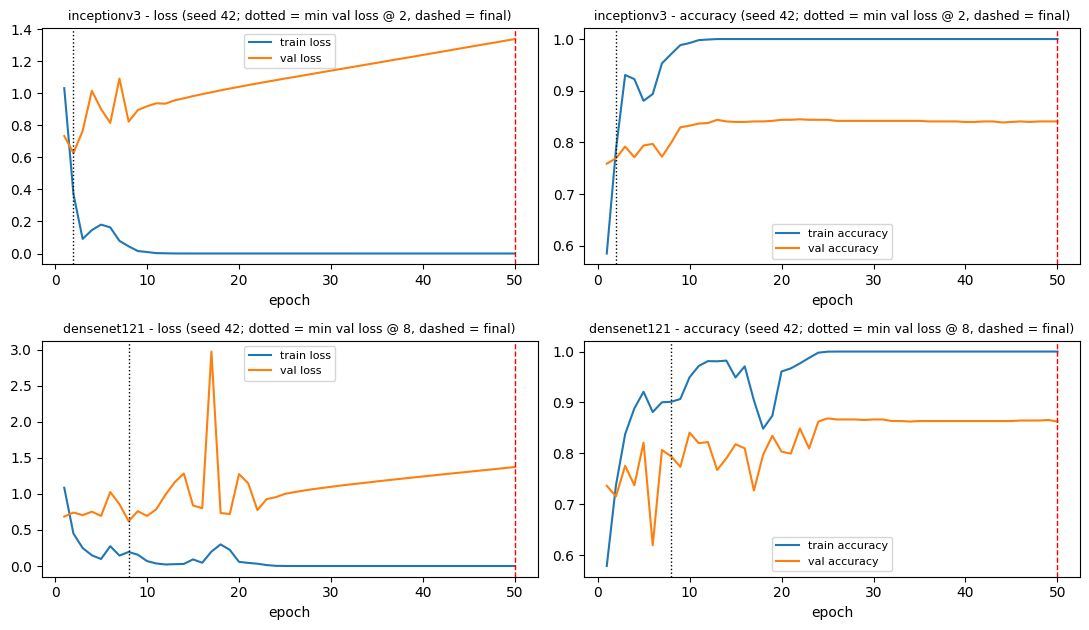

Done. Run the next (ARM, SEED), then notebook 03.


In [12]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(len(BACKBONES), 2, figsize=(11, 3.2 * len(BACKBONES)), squeeze=False)
for r, name in enumerate(BACKBONES):
    h = pd.read_csv(os.path.join(CKPT_DIR, name, "history.csv"))
    be = int(h.loc[h["val_loss"].idxmin(), "epoch"]) + 1
    for c, (k, lab) in enumerate([("loss", "loss"), ("accuracy", "accuracy")]):
        ax = axes[r, c]
        ax.plot(h["epoch"] + 1, h[k], label=f"train {lab}"); ax.plot(h["epoch"] + 1, h[f"val_{k}"], label=f"val {lab}")
        ax.axvline(be, ls=":", c="k", lw=1); ax.axvline(EPOCHS, ls="--", c="r", lw=1)
        ax.set_title(f"{name} - {lab} (seed {SEED}; dotted = min val loss @ {be}, dashed = final)", fontsize=9)
        ax.set_xlabel("epoch"); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, f"training_curves_{ARM}_seed{SEED}.png"), dpi=200); plt.show()
print("Done. Run the next (ARM, SEED), then notebook 03.")

## Status of all revision runs
Run this cell any time to see what is finished.

In [13]:
rows = []
for arm, bbs in [("controlled", ["inception", "densenet", "convnext"]), ("h2_original", ["inception", "densenet"])]:
    for s in SEEDS:
        rd = os.path.join(BASE_DIR, "runs", arm, f"seed{s}", "results")
        rows.append({"arm": arm, "seed": s, **{b: os.path.isfile(os.path.join(rd, f".done_{b}")) for b in bbs},
                     "manifest": os.path.isfile(os.path.join(rd, "manifest.json"))})
print(pd.DataFrame(rows).to_string(index=False))

        arm  seed  inception  densenet convnext  manifest
 controlled    42       True      True     True      True
 controlled  1000       True      True     True      True
 controlled 50000       True      True     True      True
 controlled  2024       True      True     True      True
 controlled 31415       True      True     True      True
h2_original    42       True      True      NaN      True
h2_original  1000      False     False      NaN     False
h2_original 50000      False     False      NaN     False
h2_original  2024      False     False      NaN     False
h2_original 31415      False     False      NaN     False
